<a href="https://colab.research.google.com/github/JanethGrimaldo/AI/blob/main/EO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ejercicio 1

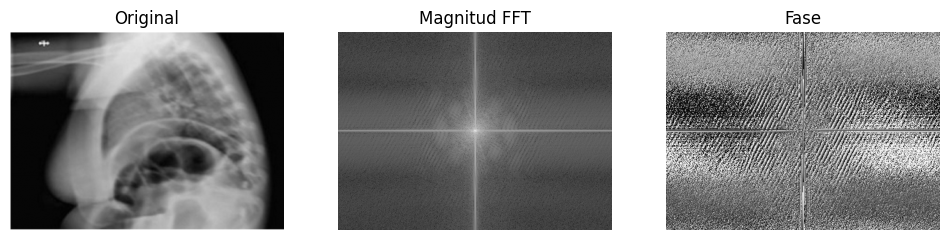

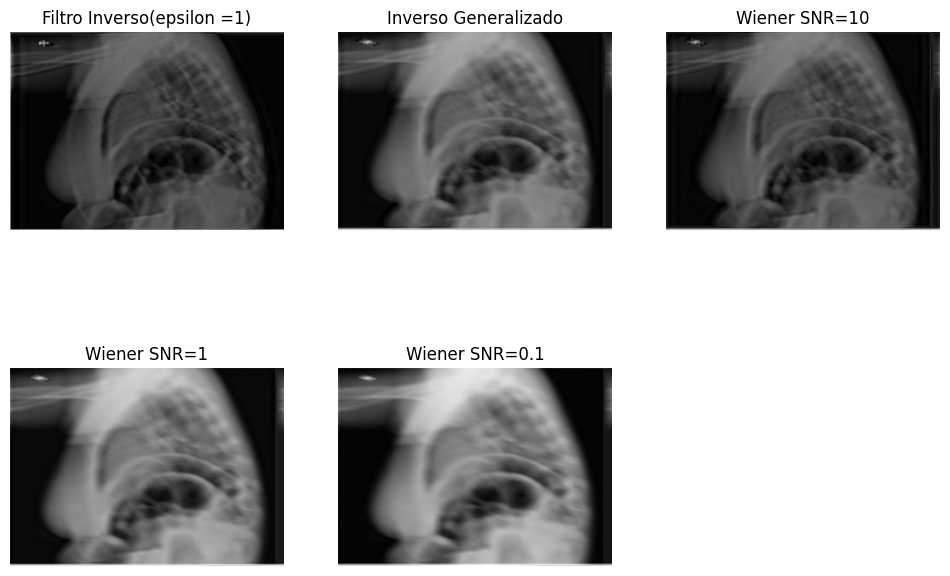

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("1.png", 0)
F = np.fft.fft2(img)
Fshift = np.fft.fftshift(F)

magnitud = np.log(np.abs(Fshift) + 1)
fase = np.angle(Fshift)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(magnitud, cmap='gray')
plt.title("Magnitud FFT")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(fase, cmap='gray')
plt.title("Fase")
plt.axis("off")

plt.show()

rows, cols = img.shape
PSF = np.zeros((rows, cols))
L = 20
centro = (rows // 2, cols // 2)

for i in range(L):
    x = int(centro[1] + i * np.cos(np.deg2rad(15)))
    y = int(centro[0] + i * np.sin(np.deg2rad(15)))

    if x < cols and y < rows:
        PSF[y, x] = 1

PSF = PSF / PSF.sum()
H = np.fft.fft2(np.fft.ifftshift(PSF))
G = np.fft.fft2(img)

eps = 1
F_inv = G / (H + eps)

img_inv = np.abs(np.fft.ifft2(F_inv))
a = 0.3
F_gen = (np.conj(H) / (np.abs(H)**2 + a)) * G

img_gen = np.abs(np.fft.ifft2(F_gen))
# filtros wiener
F_w10 = (np.conj(H) / (np.abs(H)**2 + (1 / 10))) * G
img_w10 = np.abs(np.fft.ifft2(F_w10))

F_w1 = (np.conj(H) / (np.abs(H)**2 + (1 / 1))) * G
img_w1 = np.abs(np.fft.ifft2(F_w1))

F_w01 = (np.conj(H) / (np.abs(H)**2 + (1 / 0.1))) * G
img_w01 = np.abs(np.fft.ifft2(F_w01))

plt.figure(figsize=(12, 8))
plt.subplot(2, 3, 1)
plt.imshow(img_inv, cmap='gray')
plt.title(f"Filtro Inverso(epsilon ={eps})")
plt.axis("off")
plt.subplot(2, 3, 2)
plt.imshow(img_gen, cmap='gray')
plt.title("Inverso Generalizado")
plt.axis("off")
plt.subplot(2, 3, 3)
plt.imshow(img_w10, cmap='gray')
plt.title(f"Wiener SNR=10")
plt.axis("off")
plt.subplot(2, 3, 4)
plt.imshow(img_w1, cmap='gray')
plt.title(f"Wiener SNR=1")
plt.axis("off")
plt.subplot(2, 3, 5)
plt.imshow(img_w01, cmap='gray')
plt.title(f"Wiener SNR=0.1")
plt.axis("off")

plt.show()

# Ejercicio 2


Número de células detectadas: 4
Célula 1
Área = 842.00 pixeles
Perímetro = 136.08 pixeles

Célula 2
Área = 2304.50 pixeles
Perímetro = 261.58 pixeles

Célula 3
Área = 12802.00 pixeles
Perímetro = 722.70 pixeles

Célula 4
Área = 44462.50 pixeles
Perímetro = 1984.60 pixeles



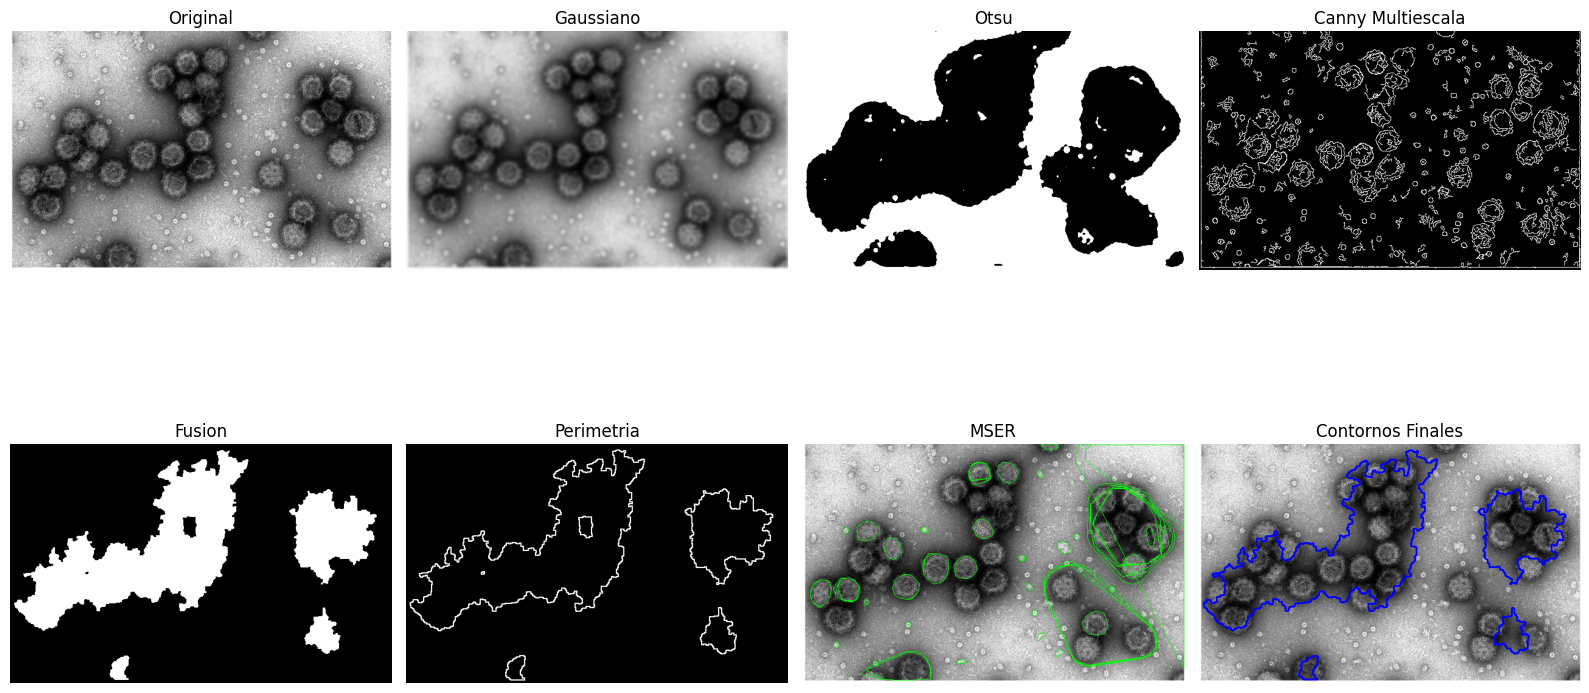

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("2.png", cv2.IMREAD_GRAYSCALE)

gauss = cv2.GaussianBlur(img, (0, 0), sigmaX=2)

_, otsu = cv2.threshold(gauss, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

canny1 = cv2.Canny(cv2.GaussianBlur(img, (0, 0), 1), 50, 150)
canny2 = cv2.Canny(cv2.GaussianBlur(img, (0, 0), 2), 50, 150)
canny4 = cv2.Canny(cv2.GaussianBlur(img, (0, 0), 4), 50, 150)

canny_multi = cv2.bitwise_or(canny1, canny2)
canny_multi = cv2.bitwise_or(canny_multi, canny4)

kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
ret, bin_img = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

bin_img = cv2.morphologyEx(bin_img, cv2.MORPH_OPEN, kernel, iterations=2)
sure_bg = cv2.dilate(bin_img, kernel, iterations=3)
dist_transform = cv2.distanceTransform(bin_img, cv2.DIST_L2, 5)
ret, sure_fg = cv2.threshold(dist_transform, 0.5 * dist_transform.max(), 255, cv2.THRESH_BINARY)
sure_fg = np.uint8(sure_fg)
unknown = cv2.subtract(sure_bg, sure_fg)
ret, markers = cv2.connectedComponents(sure_fg)

markers = markers + 1
markers[unknown == 255] = 0

img_color = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
markers = cv2.watershed(img_color, markers)

mask = np.zeros_like(img)
mask[markers > 1] = 255

cierre = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
fusion = cv2.morphologyEx(cierre, cv2.MORPH_OPEN, kernel, iterations=1)

contornos, _ = cv2.findContours(fusion, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

print("Número de células detectadas:", len(contornos))

for i, cnt in enumerate(contornos):
    area = cv2.contourArea(cnt)
    perimetro = cv2.arcLength(cnt, True)
    print(f"Célula {i+1}")
    print(f"Área = {area:.2f} pixeles")
    print(f"Perímetro = {perimetro:.2f} pixeles")
    print()

dilatada = cv2.dilate(fusion, kernel, iterations=1)
erosionada = cv2.erode(fusion, kernel, iterations=1)

perimetria = cv2.subtract(dilatada, erosionada)

mser = cv2.MSER_create()
regions, _ = mser.detectRegions(img)
mser_img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

for region in regions:
    hull = cv2.convexHull(region.reshape(-1, 1, 2))
    cv2.polylines(mser_img, [hull], True, (0, 255, 0), 1)

contornos_img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

cv2.drawContours(contornos_img, contornos, -1, (255, 0, 0), 2)

plt.figure(figsize=(16, 10))

plt.subplot(2, 4, 1)
plt.imshow(img, cmap='gray')
plt.title("Original")
plt.axis("off")

plt.subplot(2, 4, 2)
plt.imshow(gauss, cmap='gray')
plt.title("Gaussiano")
plt.axis("off")

plt.subplot(2, 4, 3)
plt.imshow(otsu, cmap='gray')
plt.title("Otsu")
plt.axis("off")

plt.subplot(2, 4, 4)
plt.imshow(canny_multi, cmap='gray')
plt.title("Canny Multiescala")
plt.axis("off")

plt.subplot(2, 4, 5)
plt.imshow(fusion, cmap='gray')
plt.title("Fusion")
plt.axis("off")

plt.subplot(2, 4, 6)
plt.imshow(perimetria, cmap='gray')
plt.title("Perimetria")
plt.axis("off")

plt.subplot(2, 4, 7)
plt.imshow(cv2.cvtColor(mser_img, cv2.COLOR_BGR2RGB))
plt.title("MSER")
plt.axis("off")

plt.subplot(2, 4, 8)
plt.imshow(cv2.cvtColor(contornos_img, cv2.COLOR_BGR2RGB))
plt.title("Contornos Finales")
plt.axis("off")

plt.tight_layout()
plt.show()

# Ejercicio 3


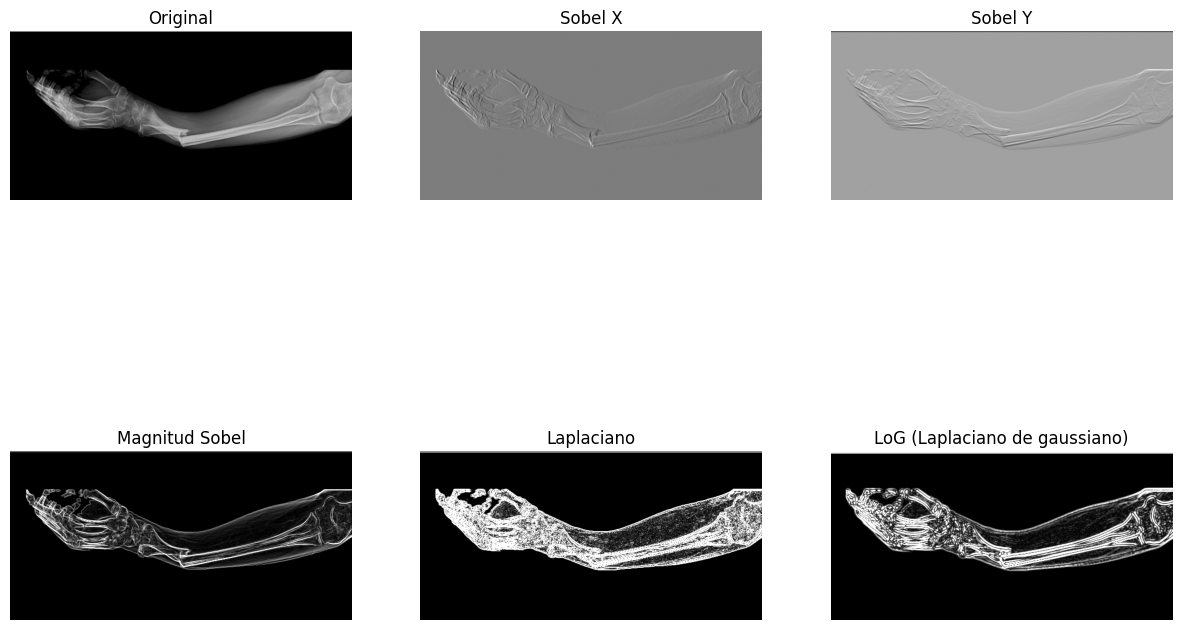

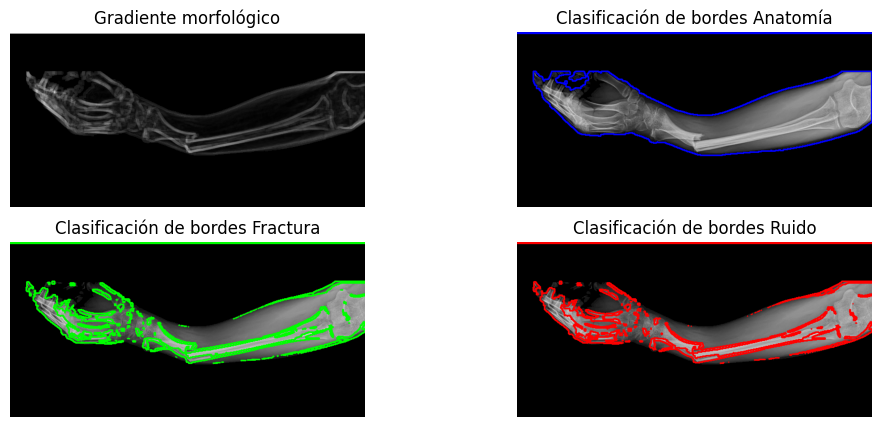

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("3.png", 0)

sobelx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)

sobely = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)

magnitud = np.sqrt(sobelx**2 + sobely**2)
magnitud = cv2.convertScaleAbs(magnitud)

lap = cv2.Laplacian(img, cv2.CV_64F, ksize=5)
lap_a = cv2.convertScaleAbs(lap)
gauss = cv2.GaussianBlur(img, (5, 5), 2)

log = cv2.Laplacian(gauss, cv2.CV_64F, ksize=5)
log_a = cv2.convertScaleAbs(log)
kernel = np.ones((5, 5), np.uint8)

grad = cv2.morphologyEx(img, cv2.MORPH_GRADIENT, kernel)
# anatomia 0,150
_, binaria_anato = cv2.threshold(grad, 0, 255, cv2.THRESH_BINARY)
contornos_anato, _ = cv2.findContours(binaria_anato, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
resultado_anato = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
color = (255, 0, 0)
cv2.drawContours(resultado_anato, contornos_anato, -1, color, 2)
resultado_rgb_anato = cv2.cvtColor(resultado_anato, cv2.COLOR_BGR2RGB)
# fractura 45,180
_, binaria_fx = cv2.threshold(grad, 55, 180, cv2.THRESH_BINARY)
contornos_fx, _ = cv2.findContours(binaria_fx, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
resultado_fx = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
color = (0, 255, 0)
cv2.drawContours(resultado_fx, contornos_fx, -1, color, 2)
resultado_rgb_fx = cv2.cvtColor(resultado_fx, cv2.COLOR_BGR2RGB)

# ruido
_, binaria_ruido = cv2.threshold(grad, 15, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
contornos_ruido, _ = cv2.findContours(binaria_ruido, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
resultado_ruido = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
for c in contornos_ruido:

    area = cv2.contourArea(c)

    if area < 10:
        color = (0, 0, 255)

    cv2.drawContours(resultado_ruido, [c], -1, color, 2)
# color = (0,255,0)
# cv2.drawContours(resultado_ruido,contornos_ruido,-1,color,2)
resultado_rgb_ruido = cv2.cvtColor(resultado_ruido, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
plt.imshow(img, cmap='gray')
plt.title("Original")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(sobelx, cmap='gray')
plt.title("Sobel X")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(sobely, cmap='gray')
plt.title("Sobel Y")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(magnitud, cmap='gray')
plt.title("Magnitud Sobel")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(lap_a, cmap='gray')
plt.title("Laplaciano")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(log_a, cmap='gray')
plt.title("LoG (Laplaciano de gaussiano)")
plt.axis("off")

plt.show()

plt.figure(figsize=(12, 5))

plt.subplot(2, 2, 1)
plt.imshow(grad, cmap='gray')
plt.title("Gradiente morfológico")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(resultado_rgb_anato)
plt.title("Clasificación de bordes Anatomía")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(resultado_rgb_fx)
plt.title("Clasificación de bordes Fractura")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(resultado_rgb_ruido)
plt.title("Clasificación de bordes Ruido")
plt.axis("off")

plt.show()